# Data Cleaning and Preprocessing: Best-Selling Game Consoles

**Student:** *Add your name*  
**Course/Class:** *Add course details*  
**Dataset:** Best-Selling Game Consoles of All Time

## 1. Objective
This notebook inspects, cleans, and preprocesses a dataset describing game consoles, their type and manufacturer, release/discontinuation years, estimated lifetime units sold (in millions), and remarks. The goal is to demonstrate reproducible data-quality checks and prepare a model-ready feature table. There is **no explicit prediction target in the original dataset**, so this notebook treats `Units sold (million)` as a possible target for a future supervised-learning task, but does not train a model.

## 2. Dataset description
- **Kaggle source:** [Best-Selling Game Consoles of All Time](https://www.kaggle.com/datasets/tayyarhussain/best-selling-game-consoles-of-all-time)
- **Local input:** `best-selling game consoles.csv` (provided in the uploaded ZIP)
- **Unit of observation:** one console/platform per row.
- **Important limitation:** sales values are reported in millions and may be approximate or stated as minimums in `Remarks`; results should not be interpreted as perfectly comparable audited figures.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

DATA_PATH = "/content/best-selling%20game%20consoles.csv"

df_raw = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_raw.shape)
display(df_raw.head())



Dataset shape: (51, 7)


,Console Name,Type,Company,Released Year,Discontinuation Year,Units sold (million),Remarks
0,PlayStation 2,Home,Sony,2000,2013,155.00,Final sales are greater than 155 million
1,Nintendo DS,Handheld,Nintendo,2004,2013,154.02,NaN
2,Nintendo Switch,Hybrid,Nintendo,2017,0,122.55,NaN
3,Game Boy,Handheld,Nintendo,1989,2003,64.42,The Game Boy (1989) and the Game Boy Color (19...
4,Game Boy Color,Handheld,Nintendo,1998,2003,44.06,NaN


### Dataset structure
The uploaded file contains 51 rows and 7 columns. Columns include:
- `Console Name`: unique console/platform name
- `Type`: console category
- `Company`: manufacturer
- `Released Year`, `Discontinuation Year`: year fields
- `Units sold (million)`: numeric lifetime sales figure, in millions
- `Remarks`: explanatory notes; blank for many records


In [6]:
print("Rows, columns:", df_raw.shape)
display(pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(1),
    "unique_values": df_raw.nunique(dropna=True)
}))
display(df_raw.describe(include="all").T)


Rows, columns: (51, 7)


,dtype,missing_count,missing_percent,unique_values
Console Name,object,0,0.0,51
Type,object,0,0.0,5
Company,object,0,0.0,15
Released Year,int64,0,0.0,30
Discontinuation Year,int64,0,0.0,30
Units sold (million),float64,0,0.0,42
Remarks,object,35,68.6,12


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Console Name,51,51,PlayStation 2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,51,5,Home,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Company,51,15,Nintendo,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Released Year,51.0,NaN,NaN,NaN,1996.058824,12.378064,1976.0,1987.5,1994.0,2004.5,2020.0
Discontinuation Year,51.0,NaN,NaN,NaN,1844.803922,543.657319,0.0,1992.0,1998.0,2011.5,2020.0
Units sold (million),51.0,NaN,NaN,NaN,35.549412,42.608844,1.0,3.2,13.56,60.205,155.0
Remarks,16,12,Final sales are greater than 1 million,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data cleaning

We preserve `df_raw` so every decision can be compared with the original. Cleaning is rule-based and conservative: do not delete unusual values merely because they are statistically extreme; first check whether they are plausible or indicate an error.


### 3.1 Standardize column names and text
Column names are converted to lowercase snake_case to make code easier to maintain. Text columns are stripped of leading/trailing whitespace. This changes formatting, not the meaning of values.


In [7]:
df = df_raw.copy()
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True)
              .str.strip("_"))
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].map(lambda x: x.strip() if isinstance(x, str) else x)

display(df.head())
print(df.columns.tolist())


,console_name,type,company,released_year,discontinuation_year,units_sold_million,remarks
0,PlayStation 2,Home,Sony,2000,2013,155.00,Final sales are greater than 155 million
1,Nintendo DS,Handheld,Nintendo,2004,2013,154.02,NaN
2,Nintendo Switch,Hybrid,Nintendo,2017,0,122.55,NaN
3,Game Boy,Handheld,Nintendo,1989,2003,64.42,The Game Boy (1989) and the Game Boy Color (19...
4,Game Boy Color,Handheld,Nintendo,1998,2003,44.06,NaN


['console_name', 'type', 'company', 'released_year', 'discontinuation_year', 'units_sold_million', 'remarks']


### 3.2 Missing values
The only column with missing values is `remarks`. These blanks mean “no additional note supplied”, not missing sales or missing identity. We replace them with the explicit category `No additional remarks` so the information remains available and downstream encoders can handle it. No rows are dropped for missingness.


In [8]:
missing_before = df.isna().sum()
print("Missing values before handling:\n", missing_before)
df["remarks"] = df["remarks"].fillna("No additional remarks")
print("\nMissing values after handling:\n", df.isna().sum())


Missing values before handling:
 console_name             0
type                     0
company                  0
released_year            0
discontinuation_year     0
units_sold_million       0
remarks                 35
dtype: int64

Missing values after handling:
 console_name            0
type                    0
company                 0
released_year           0
discontinuation_year    0
units_sold_million      0
remarks                 0
dtype: int64


### 3.3 Duplicate records
Exact duplicate rows are checked and removed if present. Console names are also checked for duplicate labels. Duplicate console names should be investigated because this table is intended to have one row per console/platform.


In [9]:
exact_duplicates = int(df.duplicated().sum())
duplicate_names = df[df["console_name"].duplicated(keep=False)].sort_values("console_name")
print("Exact duplicate rows:", exact_duplicates)
print("Repeated console names:")
display(duplicate_names if not duplicate_names.empty else pd.DataFrame(columns=df.columns))
df = df.drop_duplicates().copy()


Exact duplicate rows: 0
Repeated console names:


,console_name,type,company,released_year,discontinuation_year,units_sold_million,remarks


### 3.4 Data types and logical consistency
Year fields should be integers, and sales should be numeric. A zero in `discontinuation_year` is treated as a sentinel for “not discontinued / year not supplied” rather than a real calendar year, so it is converted to missing. We add `is_discontinued_year_known` to preserve that distinction.

A logical check flags rows where discontinuation precedes release. Such cases are not automatically overwritten: the source should be checked before changing historical facts. The dataset contains at least one suspicious case, so we mark it for review and set the derived `years_in_market` to missing for logically invalid intervals.


In [10]:
# Coerce to numeric safely before assigning types.
for col in ["released_year", "discontinuation_year", "units_sold_million"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 0 is not a plausible discontinuation year; treat as unknown/currently not specified.
df["is_discontinued_year_known"] = df["discontinuation_year"].notna() & (df["discontinuation_year"] != 0)
df.loc[df["discontinuation_year"] == 0, "discontinuation_year"] = np.nan

df["released_year"] = df["released_year"].astype("Int64")
df["discontinuation_year"] = df["discontinuation_year"].astype("Int64")
df["units_sold_million"] = df["units_sold_million"].astype(float)

df["invalid_year_interval"] = (
    df["discontinuation_year"].notna()
    & df["released_year"].notna()
    & (df["discontinuation_year"] < df["released_year"])
)
print("Rows with discontinuation before release:", int(df["invalid_year_interval"].sum()))
display(df.loc[df["invalid_year_interval"],
               ["console_name", "released_year", "discontinuation_year", "remarks"]])

df["years_in_market"] = (
    df["discontinuation_year"] - df["released_year"]
).where(~df["invalid_year_interval"])


Rows with discontinuation before release: 1


,console_name,released_year,discontinuation_year,remarks
44,Magnavox Odyssey,1978,1975,No additional remarks


### 3.5 Inconsistent categories
We inspect category labels and manufacturer labels rather than guessing replacements. Because the file has a small number of categories, the unique values are printed for manual review. Only whitespace is normalized automatically; semantic renaming should be done only when the intended category is unambiguous.


In [11]:
for col in ["type", "company"]:
    print(f"\n{col} categories ({df[col].nunique()}):")
    print(sorted(df[col].dropna().unique().tolist()))



type categories (5):
['Dedicated', 'Handheld', 'Home', 'Home console add-on', 'Hybrid']

company categories (15):
['Atari', 'Bandai', 'Coleco', 'Magnavox/Philips', 'Mattel', 'Micro Genius', 'Microsoft', 'NEC', 'NEC/Hudson Soft[note 6]', 'Nintendo', 'Nokia', 'Philips', 'Sega', 'Sony', 'Tectoy']


### 3.6 Outlier inspection
`units_sold_million` is right-skewed: a small number of highly successful consoles have much larger sales than most rows. These are plausible observations, not necessarily errors, so we **retain** them. We use the IQR rule to flag potential outliers for review, and later apply `log1p` to reduce skew for modeling. The transformation is not a deletion rule.


IQR lower/upper fences: -82.31, 145.71 million
Potential outliers flagged: 2


,console_name,units_sold_million,sales_iqr_outlier_flag
0,PlayStation 2,155.00,True
1,Nintendo DS,154.02,True


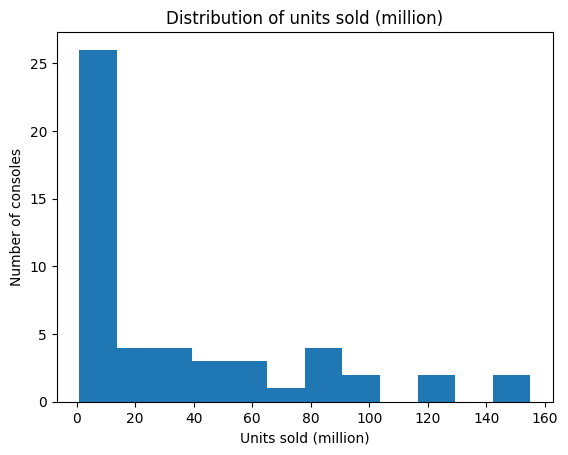

In [12]:
sales = df["units_sold_million"].dropna()
q1, q3 = sales.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
df["sales_iqr_outlier_flag"] = (df["units_sold_million"] < lower) | (df["units_sold_million"] > upper)
print(f"IQR lower/upper fences: {lower:.2f}, {upper:.2f} million")
print("Potential outliers flagged:", int(df["sales_iqr_outlier_flag"].sum()))
display(df.loc[df["sales_iqr_outlier_flag"],
               ["console_name", "units_sold_million", "sales_iqr_outlier_flag"]]
        .sort_values("units_sold_million", ascending=False))

fig, ax = plt.subplots()
ax.hist(df["units_sold_million"].dropna(), bins=12)
ax.set_title("Distribution of units sold (million)")
ax.set_xlabel("Units sold (million)")
ax.set_ylabel("Number of consoles")
plt.show()


## 4. Data preprocessing

### 4.1 Feature and target decision
The source has no labeled prediction target. For an illustrative future regression task, `units_sold_million` could be the target, with console type, manufacturer, release year, and other known-at-release features as predictors. However, `remarks` may contain sales-related statements and `discontinuation_year` may encode information only known after a console's lifecycle, so they are excluded from the illustrative predictor set to reduce target leakage.

For a real prediction task, define the prediction time first and only use features available at that time.


In [13]:
# Variable roles
variable_roles = pd.DataFrame([
    ["console_name", "Identifier / nominal text", "Usually exclude from numeric model; optional high-cardinality encoding"],
    ["type", "Categorical nominal", "One-hot encode"],
    ["company", "Categorical nominal", "One-hot encode"],
    ["released_year", "Numerical discrete / year", "Standardize if model benefits"],
    ["discontinuation_year", "Year; often unavailable at release", "Exclude from release-time prediction to avoid leakage"],
    ["units_sold_million", "Numerical continuous", "Possible target; log1p transform for skew"],
    ["remarks", "Free text / notes", "Exclude from model because may reveal sales outcomes"],
    ["years_in_market", "Derived numerical", "Potential leakage if predicting sales at release"],
    ["is_discontinued_year_known", "Binary", "Use only if valid at prediction time"],
], columns=["feature", "variable_type", "handling"])
display(variable_roles)


,feature,variable_type,handling
0,console_name,Identifier / nominal text,Usually exclude from numeric model; optional h...
1,type,Categorical nominal,One-hot encode
2,company,Categorical nominal,One-hot encode
3,released_year,Numerical discrete / year,Standardize if model benefits
4,discontinuation_year,Year; often unavailable at release,Exclude from release-time prediction to avoid ...
5,units_sold_million,Numerical continuous,Possible target; log1p transform for skew
6,remarks,Free text / notes,Exclude from model because may reveal sales ou...
7,years_in_market,Derived numerical,Potential leakage if predicting sales at release
8,is_discontinued_year_known,Binary,Use only if valid at prediction time


### 4.2 Engineered features and skew transformation
We create `release_decade` to summarize release era, and `log_units_sold` using `log1p` to compress the long right tail. The latter is suitable for exploration or as a transformed target, but a model's predictions would need to be converted back using `expm1`.


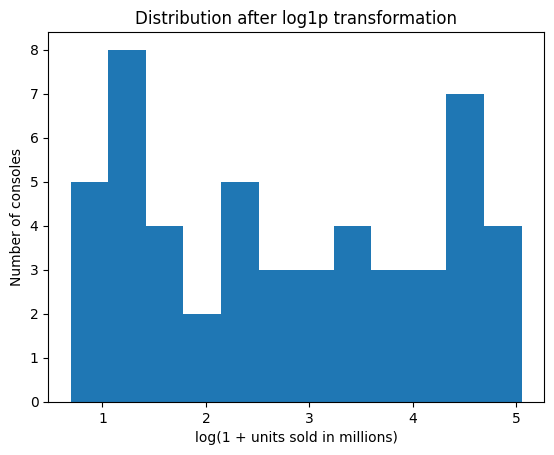

,console_name,released_year,release_decade,units_sold_million,log_units_sold
0,PlayStation 2,2000,2000,155.00,5.049856
1,Nintendo DS,2004,2000,154.02,5.043554
2,Nintendo Switch,2017,2010,122.55,4.816646
3,Game Boy,1989,1980,64.42,4.180828
4,Game Boy Color,1998,1990,44.06,3.807995


In [14]:
df["release_decade"] = ((df["released_year"] // 10) * 10).astype("Int64")
df["log_units_sold"] = np.log1p(df["units_sold_million"])

fig, ax = plt.subplots()
ax.hist(df["log_units_sold"].dropna(), bins=12)
ax.set_title("Distribution after log1p transformation")
ax.set_xlabel("log(1 + units sold in millions)")
ax.set_ylabel("Number of consoles")
plt.show()

display(df[["console_name", "released_year", "release_decade",
            "units_sold_million", "log_units_sold"]].head())


### 4.3 Encoding and scaling without leakage
The following creates a preprocessing pipeline for a hypothetical regression task. The train/test split happens **before** fitting encoders and scalers. `OneHotEncoder` and `StandardScaler` are fitted only on training data through the pipeline. This prevents test-set statistics/categories from influencing training.

Because the dataset is very small (about 50 rows), any model evaluation would have high uncertainty. The pipeline is included to demonstrate proper practice, not to claim a reliable predictive model.


In [15]:
# Illustrative target and predictors; exclude post-lifecycle/remarks fields.
model_df = df.dropna(subset=["units_sold_million", "released_year", "type", "company"]).copy()
X = model_df[["type", "company", "released_year"]]
y = np.log1p(model_df["units_sold_million"])  # transformed target for skew

categorical_features = ["type", "company"]
numeric_features = ["released_year"]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", StandardScaler(), numeric_features),
    ],
    remainder="drop"
)

# Split before fitting any preprocessing step.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Training rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])
print("Prepared training matrix shape:", X_train_prepared.shape)
print("Prepared test matrix shape:", X_test_prepared.shape)
print("Encoded feature names:")
print(preprocessor.get_feature_names_out().tolist())


Training rows: 40 | Test rows: 11
Prepared training matrix shape: (40, 19)
Prepared test matrix shape: (11, 19)
Encoded feature names:
['categorical__type_Dedicated', 'categorical__type_Handheld', 'categorical__type_Home', 'categorical__type_Home console add-on', 'categorical__type_Hybrid', 'categorical__company_Atari', 'categorical__company_Bandai', 'categorical__company_Coleco', 'categorical__company_Magnavox/Philips', 'categorical__company_Mattel', 'categorical__company_Microsoft', 'categorical__company_NEC', 'categorical__company_NEC/Hudson Soft[note 6]', 'categorical__company_Nintendo', 'categorical__company_Nokia', 'categorical__company_Philips', 'categorical__company_Sega', 'categorical__company_Sony', 'numeric__released_year']


### 4.4 Final validation and export
We validate the cleaned table, summarize the changes, and export a cleaned CSV. The output keeps source columns plus transparent flags and derived features. Review `invalid_year_interval` and flagged sales outliers before any formal analysis; flags are intentionally not silent corrections.


In [16]:
print("Final shape:", df.shape)
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count"))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Invalid year intervals:", int(df["invalid_year_interval"].sum()))
print("Sales outlier flags:", int(df["sales_iqr_outlier_flag"].sum()))

# Keep a cleaned analysis table; retain NaN for unknown discontinuation year.
df.to_csv("best_selling_game_consoles_cleaned.csv", index=False)
print("Saved: best_selling_game_consoles_cleaned.csv")
display(df.head())


Final shape: (51, 13)
Missing values by column:


,missing_count
console_name,0
type,0
company,0
released_year,0
discontinuation_year,4
units_sold_million,0
remarks,0
is_discontinued_year_known,0
invalid_year_interval,0
years_in_market,5


Exact duplicate rows: 0
Invalid year intervals: 1
Sales outlier flags: 2
Saved: best_selling_game_consoles_cleaned.csv


,console_name,type,company,released_year,discontinuation_year,units_sold_million,remarks,is_discontinued_year_known,invalid_year_interval,years_in_market,sales_iqr_outlier_flag,release_decade,log_units_sold
0,PlayStation 2,Home,Sony,2000,2013,155.00,Final sales are greater than 155 million,True,False,13,True,2000,5.049856
1,Nintendo DS,Handheld,Nintendo,2004,2013,154.02,No additional remarks,True,False,9,True,2000,5.043554
2,Nintendo Switch,Hybrid,Nintendo,2017,<NA>,122.55,No additional remarks,False,False,<NA>,False,2010,4.816646
3,Game Boy,Handheld,Nintendo,1989,2003,64.42,The Game Boy (1989) and the Game Boy Color (19...,True,False,14,False,1980,4.180828
4,Game Boy Color,Handheld,Nintendo,1998,2003,44.06,No additional remarks,True,False,5,False,1990,3.807995


## 5. Conclusion
- Missing values occurred in `remarks`; they were labeled as “No additional remarks” rather than dropping records.
- No exact duplicate records were expected; the notebook checks and removes exact duplicates if any are found.
- Year and sales columns were converted to numeric types, and zero discontinuation years were treated as unknown/sentinel values.
- Discontinuation-before-release records were flagged rather than silently edited.
- High sales values were retained because they are plausible; IQR flags and a log transform support investigation and modeling.
- Categorical predictors are one-hot encoded and the release year is standardized in a pipeline fitted only on training data.
- There is no explicit target in the original data; `units_sold_million` is only a suggested target for a future task.

## 6. Submission checklist
1. Run every cell in Google Colab or Kaggle Notebook and confirm outputs appear.
2. Upload the CSV alongside the notebook, or update `DATA_PATH` to the correct location.
3. Add your name/course details and optionally screenshots of important outputs.
4. Save the `.ipynb` and cleaned CSV to a public GitHub repository or Zenodo record.
5. Open the repository link in a private/incognito window to confirm access, then submit that link on LMS.

**Important:** The notebook is a starting point. Read each explanation and be prepared to explain why each decision was made.
